In [22]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn. neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score , mean_absolute_error

In [24]:
df = pd.read_csv(r"D:\AI-ML_class\knn_data.csv",
)
df.head()

,Weight,Sweetness,Fruit
0,161.236204,5.366115,Apple
1,178.521429,6.485531,Apple
2,171.959818,5.103166,Apple
3,167.959755,7.727961,Apple
4,154.680559,5.776340,Apple


In [25]:
print(df.shape)
print(df["Fruit"].value_counts())

(120, 3)
Fruit
Apple    40
Lemon    40
Grape    40
Name: count, dtype: int64


In [26]:
df.isnull().sum()

Weight       0
Sweetness    0
Fruit        0
dtype: int64

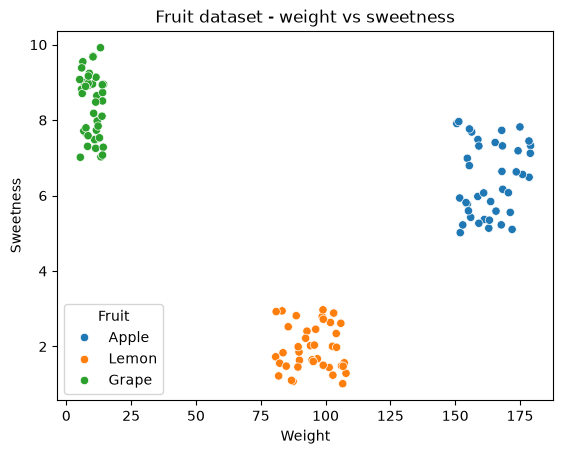

In [27]:
sns.scatterplot(
    data=df,
    x="Weight",
    y="Sweetness",
    hue="Fruit"
)

plt.title("Fruit dataset - weight vs sweetness")
plt.show()


In [28]:
X= df[["Weight", "Sweetness"]]

y = df["Fruit"]

X_train, X_test, y_train, y_test = train_test_split(

X, y,

test_size=0.2,

random_state=42

)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train_scaled.shape)

print("Test size", X_test_scaled.shape)

Train size: (96, 2)
Test size (24, 2)


In [29]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [30]:
y_pred = knn.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


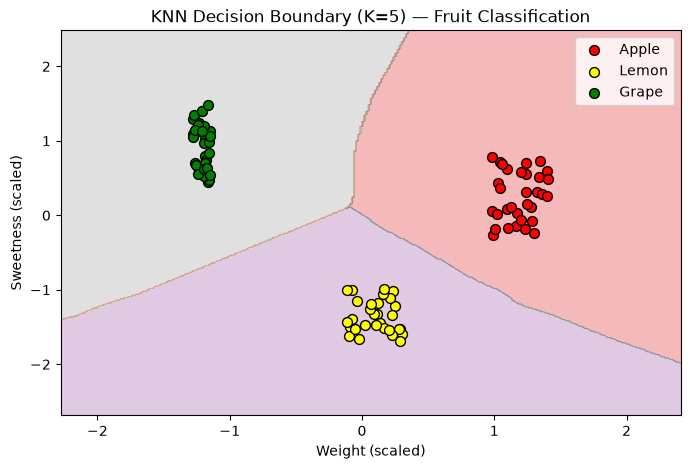

In [32]:
# ==========================================
# STEP 6: DECISION BOUNDARY PLOT
# ==========================================

x1 = X_train_scaled[:, 0]
x2 = X_train_scaled[:, 1]

xx, yy = np.meshgrid(
    np.linspace(x1.min()-1, x1.max()+1, 300),
    np.linspace(x2.min()-1, x2.max()+1, 300)
)

Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])

label_map = {"Apple": 0, "Lemon": 1, "Grape": 2}
Z_num = np.array([label_map[z] for z in Z]).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z_num, alpha=0.3, cmap="Set1")

color_map = {"Apple": "red", "Lemon": "yellow", "Grape": "green"}
for fruit, color in color_map.items():
    idx = y_train == fruit
    plt.scatter(
        x1[idx], x2[idx],
        label=fruit,
        color=color,
        edgecolors='black',
        s=50
    )

plt.title("KNN Decision Boundary (K=5) — Fruit Classification")
plt.xlabel("Weight (scaled)")
plt.ylabel("Sweetness (scaled)")
plt.legend()
plt.show()